# V2 — Stealing-Guided Word-Bigram Substitution

**Trustworthy AI seminar · Break the Watermark! · Single-notebook experiment**

**Research question:** do **word-bigram frequency differences** between watermarked (WM) and non-watermarked (NoWM) text identify positions that are more effective to perturb than V1 unigram statistics?

- **Reuses** the 600 aligned WM/NoWM pairs, the original detector baseline and the same 10 stratified 400/200 splits as V1.
- **V2 pure:** word-bigram scores select positions; WordNet supplies replacements. Compare position rankings, random replacement and context-guided replacement.
- **V2 hybrid:** first target bigram positions, then use unigram positions to fill unused substitution budget.
- **Matched-edit experiment:** compare V1, V2 and random controls with **exactly the same number of actual substitutions per text**. The hybrid and native V1 are analyzed separately because coverage differs.
- **Persistence:** validated configuration, checkpoint per `(min_support, split_seed, ratio)`, restart safely, export reproducible summaries and exact paired McNemar tests.

**Limitations:** The WM/NoWM unigram and bigram frequencies are **proxies**, not the detector's token greenlist. The 10 train/test splits overlap, and these 600 examples were already used in V1 development: all tests are **exploratory**, not independent confirmation. The experiment does not measure semantic preservation (following the selected protocol).

**Run location:** `notebooks/03_our_attacks/v2_bigram/stealing_guided_v2.ipynb` (any current working directory under the repo). No LLaDA text generation is performed here; only the existing watermark detector is loaded.

## 1 — Setup, dependencies and experiment settings

All parameters are declared here. **Do not change parameters after generating checkpoints** without changing `EXPERIMENT_ID` or moving the previous output directory. For a short pilot, change `RUN_SPLIT_SEEDS` / `RUN_SUPPORTS`, which select a subset of the locked full experiment without changing its definition. The default runs the entire experiment.

In [12]:
import hashlib
import json
import math
import random
import re
import sys
import tempfile
import time
from collections import Counter, defaultdict
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from nltk.corpus import wordnet
from scipy.stats import binomtest
from tqdm.auto import tqdm


def find_project_root(start: Path) -> Path:
    for folder in (start, *start.parents):
        if (folder / "src" / "detection.py").is_file() and (
            folder / "results" / "Cleaned Data"
        ).is_dir():
            return folder
    raise FileNotFoundError("Run inside the project containing src/detection.py and results/Cleaned Data")

ROOT = find_project_root(Path.cwd().resolve())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from detection import detect, load_detector, load_jsonl

EXPERIMENT_ID = "v2_word_bigram_v1_2026_11_21"
SPLIT_SEEDS = [42, 100, 101, 102, 103, 104, 105, 106, 107, 108]
MIN_SUPPORTS = [2, 5]             # bigram and matched V1 unigram support
RATIOS = [0.1, 0.2, 0.3, 0.4, 0.5]
ALPHA = 0.5
REFERENCE_SEED = 42
REFERENCE_SUPPORT = 2

# Optional subsets for a pilot. Restore full lists to complete the experiment.
RUN_SPLIT_SEEDS = SPLIT_SEEDS
RUN_SUPPORTS = MIN_SUPPORTS
STORE_ATTACKED_TEXT = False     # set True before first run if you need large text checkpoints

METHODS_MATCHED = [
    "v2_sum_random", "v2_sum_guided", "v2_max_random",
    "v2_random_pool", "v1_score_random_matched", "random_wordnet_matched",
]
METHODS_DESCRIPTIVE = ["v2_hybrid_random", "v1_score_random_native"]
METHODS = METHODS_MATCHED + METHODS_DESCRIPTIVE
WORD_PATTERN = re.compile(r"[a-z]+(?:'[a-z]+)?")

OUT_DIR = ROOT / "results" / "attacks" / "stealing_guided_v2_bigram"
CHECKPOINT_DIR = OUT_DIR / "checkpoints"
OUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

try:
    assert len(wordnet.synsets("important")) > 0
except LookupError as exc:
    raise RuntimeError("NLTK WordNet missing. In your .venv run: import nltk; nltk.download('wordnet')") from exc

assert set(RUN_SPLIT_SEEDS).issubset(SPLIT_SEEDS)
assert set(RUN_SUPPORTS).issubset(MIN_SUPPORTS)
print("Root:", ROOT)
print("Output:", OUT_DIR)
print("Planned supports:", RUN_SUPPORTS, "| splits:", RUN_SPLIT_SEEDS, "| ratios:", RATIOS)

Root: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking
Output: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v2_bigram
Planned supports: [2, 5] | splits: [42, 100, 101, 102, 103, 104, 105, 106, 107, 108] | ratios: [0.1, 0.2, 0.3, 0.4, 0.5]


## 2 — Data provenance and exact V1 splits

Indices are aligned across WM, NoWM and the pre-attack detection baseline. The split function follows notebook 11 **exactly**: sorted dataset groups and 134/133/133 training examples. No test text enters word-frequency estimates for its own split. The input SHA-256 hashes protect checkpoint reuse.

In [13]:
WM_PATH = ROOT / "results" / "Cleaned Data" / "watermarked_600.jsonl"
NOWM_PATH = ROOT / "results" / "Cleaned Data" / "unwatermarked_600.jsonl"
BASELINE_PATH = ROOT / "results" / "attacks" / "baseline_original.jsonl"
DETECTION_PY = ROOT / "src" / "detection.py"

wm = load_jsonl(WM_PATH)
no_wm = load_jsonl(NOWM_PATH)
baseline_rows = load_jsonl(BASELINE_PATH)
assert len(wm) == len(no_wm) == len(baseline_rows) == 600
baseline_by_idx = {int(r["idx"]): r for r in baseline_rows}
assert set(baseline_by_idx) == set(range(600)), "Baseline must contain unique indices 0..599"


def dataset_id(row):
    return row["dataset_name"].split("_batch_")[0]


groups = defaultdict(list)
for idx in range(600):
    assert wm[idx]["prompt"] == no_wm[idx]["prompt"] == baseline_by_idx[idx]["prompt"]
    assert dataset_id(wm[idx]) == dataset_id(no_wm[idx])
    assert wm[idx]["completion"] and no_wm[idx]["completion"]
    groups[dataset_id(wm[idx])].append(idx)
assert len(groups) == 3 and sorted(map(len, groups.values())) == [200, 200, 200]


def make_split(seed):
    rng = random.Random(seed)
    train, test = [], []
    for j, (_, original_indices) in enumerate(sorted(groups.items())):
        indices = original_indices.copy()
        rng.shuffle(indices)
        n_train = 134 if j == 0 else 133
        train.extend(indices[:n_train])
        test.extend(indices[n_train:])
    train, test = sorted(train), sorted(test)
    assert len(train) == 400 and len(test) == 200
    assert set(train).isdisjoint(test) and set(train) | set(test) == set(range(600))
    return train, test


def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for part in iter(lambda: handle.read(1024 * 1024), b""):
            h.update(part)
    return h.hexdigest()


input_hashes = {str(p.relative_to(ROOT)): file_sha256(p)
                for p in [WM_PATH, NOWM_PATH, BASELINE_PATH, DETECTION_PY]}
config = {
    "experiment_id": EXPERIMENT_ID,
    "split_seeds": SPLIT_SEEDS,
    "min_supports": MIN_SUPPORTS,
    "ratios": RATIOS,
    "alpha": ALPHA,
    "methods": METHODS,
    "store_attacked_text": STORE_ATTACKED_TEXT,
    "input_sha256": input_hashes,
    "notes": "Unigram V1 reimplemented for edit-matched control; same split and score definition as notebook 11",
}
config_path = OUT_DIR / "config.json"
if config_path.exists():
    assert json.loads(config_path.read_text(encoding="utf-8")) == config, (
        "Existing V2 config or input fingerprints differ. Do not reuse checkpoints; "
        "choose a new EXPERIMENT_ID / output folder first."
    )
    print("Existing configuration verified: safe to resume")
else:
    config_path.write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")
    print("New experiment configuration saved")

train42, test42 = make_split(42)
assert sum(bool(baseline_by_idx[i]["detected"]) for i in test42) == 195
print("WM initially detected:", sum(bool(row["detected"]) for row in baseline_rows), "/600")
print("Reference split 42:", len(train42), "train,", len(test42), "test, 195 eligible")
print("Dataset groups:", {ds: len(ids) for ds, ids in sorted(groups.items())})

Existing configuration verified: safe to resume
WM initially detected: 583 /600
Reference split 42: 400 train, 200 test, 195 eligible
Dataset groups: {'2-1_longform_qa': 200, '2-2_finance_qa': 200, '5-1_alpacafarm': 200}


## 3 — Statistical models: unigram V1 and word-bigram V2

We estimate word or bigram frequencies on the **training pairs only**:

\[
S(x)=\log \frac{(c_{WM}(x)+\alpha)/(N_{WM}+\alpha V)}
                  {(c_{NoWM}(x)+\alpha)/(N_{NoWM}+\alpha V)}
\]

`V` is the number of types observed in either group; `N` counts training unigram/bigram occurrences. V2 uses the same `ALPHA=0.5` as V1.

**Pure V2 eligibility:** a position has at least one WordNet replacement and a *positive sum* of its left/right bigram scores, using only bigrams with total support >= `MIN_SUPPORT`. An unsupported or unseen context contributes **zero evidence**, **not** a favorable negative score. The score-max variant uses the same candidate pool, only a different ordering.

**V1 comparator:** reproduces V1's unigram dictionary rule (positive original score, original and best candidate support >= threshold, candidate score lower). Training on the same split lets us evaluate a **strict equal-edit** V1 comparator.

In [14]:
def tokenize_words(text):
    return WORD_PATTERN.findall(text.lower())


@lru_cache(maxsize=None)
def get_synonyms(word):
    candidates = set()
    for synset in wordnet.synsets(word):
        for lemma in synset.lemmas():
            candidate = lemma.name().lower()
            if candidate != word and re.fullmatch(r"[a-z]+", candidate):
                candidates.add(candidate)
    return tuple(sorted(candidates))


def smoothed_log_ratio(wm_counts, no_counts, alpha):
    vocabulary = set(wm_counts) | set(no_counts)
    v = len(vocabulary)
    if not v:
        raise ValueError("Empty training corpus")
    n_wm = sum(wm_counts.values())
    n_no = sum(no_counts.values())
    scores = {
        item: math.log(((wm_counts[item] + alpha) / (n_wm + alpha * v)) /
                       ((no_counts[item] + alpha) / (n_no + alpha * v)))
        for item in vocabulary
    }
    return scores


def learn_statistics(train_ids):
    wc_wm, wc_no, bc_wm, bc_no = Counter(), Counter(), Counter(), Counter()
    for idx in train_ids:
        wm_words = tokenize_words(wm[idx]["completion"])
        no_words = tokenize_words(no_wm[idx]["completion"])
        wc_wm.update(wm_words)
        wc_no.update(no_words)
        bc_wm.update(zip(wm_words[:-1], wm_words[1:]))
        bc_no.update(zip(no_words[:-1], no_words[1:]))
    return {
        "word_wm": wc_wm, "word_no": wc_no,
        "bigram_wm": bc_wm, "bigram_no": bc_no,
        "word_scores": smoothed_log_ratio(wc_wm, wc_no, ALPHA),
        "bigram_scores": smoothed_log_ratio(bc_wm, bc_no, ALPHA),
    }


def build_v1_dictionary(statistics, support):
    wm_counts = statistics["word_wm"]
    no_counts = statistics["word_no"]
    scores = statistics["word_scores"]
    dictionary = {}
    for word in sorted(scores):
        if wm_counts[word] + no_counts[word] < support or scores[word] <= 0:
            continue
        choices = [syn for syn in get_synonyms(word)
                   if syn in scores
                   and wm_counts[syn] + no_counts[syn] >= support
                   and scores[syn] < scores[word]]
        if choices:
            best = min(choices, key=lambda s: scores[s])
            dictionary[word] = {
                "replacement": best,
                "score": scores[word],
                "gain": scores[word] - scores[best],
            }
    return dictionary


def supported_bigram_score(statistics, bigram, support):
    n = statistics["bigram_wm"][bigram] + statistics["bigram_no"][bigram]
    return statistics["bigram_scores"].get(bigram) if n >= support else None


def collect_positions(text, statistics, support, v1_dict):
    matches = list(WORD_PATTERN.finditer(text.lower()))
    words = [m.group() for m in matches]
    v2, v1, all_wordnet = [], [], []
    for i, match in enumerate(matches):
        word = words[i]
        options = get_synonyms(word)
        if not options:
            continue
        base = {
            "word_index": i, "start": match.start(), "end": match.end(),
            "original": word, "prev": words[i - 1] if i else None,
            "next": words[i + 1] if i + 1 < len(words) else None,
        }
        all_wordnet.append(base)
        if word in v1_dict:
            v1.append({**base, "score_v1": v1_dict[word]["score"]})
        local_scores = []
        if i:
            score = supported_bigram_score(statistics, (words[i - 1], word), support)
            if score is not None:
                local_scores.append(score)
        if i + 1 < len(words):
            score = supported_bigram_score(statistics, (word, words[i + 1]), support)
            if score is not None:
                local_scores.append(score)
        s = sum(local_scores)
        if local_scores and s > 0:
            v2.append({**base, "score_sum": s,
                       "score_max": max(local_scores),
                       "n_observed_contexts": len(local_scores)})
    v2.sort(key=lambda p: -p["score_sum"])  # Python stable sort = tie by text order
    v1.sort(key=lambda p: -p["score_v1"])
    return len(matches), v2, v1, all_wordnet

## 4 — Attacks, strict edit matching and context-aware replacements

**Main experiment:** set `n = min(round(r × words), V2_eligible, V1_eligible)`. All six `*_matched` / V2-pure methods edit **exactly `n` words** on the *same source text*. `v2_random_pool` samples from the **same eligible V2 positions** as the bigram ranking; `random_wordnet_matched` samples from all WordNet-replaceable positions. This distinguishes ranking skill from simply filtering to a favorable candidate set.

**Replacement controls:** random WordNet uses a stable per-position random seed, so **the same word at the same position receives the same random synonym across methods**, independent of which positions were selected. `v2_sum_guided` tries to choose the lowest-scoring synonym **only if all newly formed neighboring bigrams have adequate training support and the estimated score decreases**. Otherwise it falls back to the exact same random synonym. We report the fallback rate; sparse bigrams may make context guidance very difficult.

**Hybrid:** uses all high-scoring bigram positions up to nominal budget and then fills from V1 unigram positions not already selected. This, and `v1_score_random_native`, are **descriptive** when actual edit counts differ; they are never used as equal-budget inferential comparisons.

In [15]:
def stable_int(*parts):
    blob = "::".join(map(str, parts)).encode("utf-8")
    return int.from_bytes(hashlib.blake2b(blob, digest_size=8).digest(), "big")


def synonym_random(position, split_seed, ratio_index, idx):
    options = get_synonyms(position["original"])
    assert options
    k = stable_int("syn", split_seed, ratio_index, idx, position["word_index"]) % len(options)
    return options[k]


def synonym_guided(position, statistics, support, split_seed, ratio_index, idx):
    original = position["original"]
    best_options = []
    # Evaluate locally in the original text's immediate word context.
    contexts_original = []
    if position["prev"] is not None:
        contexts_original.append((position["prev"], original))
    if position["next"] is not None:
        contexts_original.append((original, position["next"]))
    original_score = sum(
        supported_bigram_score(statistics, pair, support) or 0.0
        for pair in contexts_original
    )
    for syn in get_synonyms(original):
        new_pairs = []
        if position["prev"] is not None:
            new_pairs.append((position["prev"], syn))
        if position["next"] is not None:
            new_pairs.append((syn, position["next"]))
        if not new_pairs:
            continue
        new_scores = [supported_bigram_score(statistics, b, support) for b in new_pairs]
        # An unseen context is UNKNOWN, not a guaranteed reduction in watermark signal.
        if any(score is None for score in new_scores):
            continue
        score = sum(new_scores)
        if score < original_score:
            best_options.append((score, syn))
    if best_options:
        return min(best_options)[1], True  # statistically supported guided replacement
    return synonym_random(position, split_seed, ratio_index, idx), False


def apply_substitutions(text, positions, replacements):
    assert len(positions) == len(replacements)
    attacked = text
    for pos, replacement in sorted(zip(positions, replacements),
                                   key=lambda pair: pair[0]["start"], reverse=True):
        surface = attacked[pos["start"]:pos["end"]]
        if surface.isupper():
            replacement = replacement.upper()
        elif surface.istitle():
            replacement = replacement.capitalize()
        assert replacement.lower() != surface.lower()
        attacked = attacked[:pos["start"]] + replacement + attacked[pos["end"]:]
    return attacked


def sample_positions(candidates, n, *seed_parts):
    rng = random.Random(stable_int("positions", *seed_parts))
    return rng.sample(candidates, n) if n else []


def build_attack_variants(text, statistics, support, v1_dict,
                          split_seed, ratio_index, idx):
    ratio = RATIOS[ratio_index]
    n_words, v2_pool, v1_pool, any_wordnet = collect_positions(
        text, statistics, support, v1_dict
    )
    target = round(n_words * ratio)
    n_matched = min(target, len(v2_pool), len(v1_pool))
    assert n_matched <= len(any_wordnet)

    rank_sum = v2_pool[:n_matched]
    rank_max = sorted(v2_pool, key=lambda p: -p["score_max"])[:n_matched]
    random_pool = sample_positions(v2_pool, n_matched,
                                   split_seed, ratio_index, idx, "v2_pool")
    v1_matched = v1_pool[:n_matched]
    global_random = sample_positions(any_wordnet, n_matched,
                                     split_seed, ratio_index, idx, "wordnet_global")

    # Hybrid fallback: never replace an already-selected word twice.
    hybrid = v2_pool[:target]
    chosen_indices = {p["word_index"] for p in hybrid}
    for pos in v1_pool:
        if len(hybrid) >= target:
            break
        if pos["word_index"] not in chosen_indices:
            hybrid.append(pos)
            chosen_indices.add(pos["word_index"])
    v1_native = v1_pool[:target]

    selected = {
        "v2_sum_random": rank_sum,
        "v2_sum_guided": rank_sum,
        "v2_max_random": rank_max,
        "v2_random_pool": random_pool,
        "v1_score_random_matched": v1_matched,
        "random_wordnet_matched": global_random,
        "v2_hybrid_random": hybrid,
        "v1_score_random_native": v1_native,
    }
    results = {}
    for method, positions in selected.items():
        n_guided = 0
        replacements = []
        for position in positions:
            if method == "v2_sum_guided":
                syn, was_guided = synonym_guided(
                    position, statistics, support, split_seed, ratio_index, idx
                )
                n_guided += int(was_guided)
            else:
                syn = synonym_random(position, split_seed, ratio_index, idx)
            replacements.append(syn)
        attacked = apply_substitutions(text, positions, replacements)
        results[method] = {
            "attacked": attacked,
            "n_replaced": len(positions),
            "n_guided_replacements": n_guided,
            "changed_word_indices": [p["word_index"] for p in positions],
        }
    assert len({results[m]["n_replaced"] for m in METHODS_MATCHED}) == 1
    assert all(results[m]["n_replaced"] == n_matched for m in METHODS_MATCHED)
    assert (results["v2_sum_random"]["changed_word_indices"] ==
            results["v2_sum_guided"]["changed_word_indices"])
    return {
        "variants": results,
        "n_words": n_words,
        "n_targeted": target,
        "n_eligible_v2": len(v2_pool),
        "n_eligible_v1": len(v1_pool),
        "n_eligible_wordnet": len(any_wordnet),
        "n_eligible_union": len({p["word_index"] for p in (v2_pool + v1_pool)}),
        "n_matched": n_matched,
    }

## 5 — Sanity checks and V1 reference consistency

We check the exact V1 split, dictionary construction and number of editable positions against the previous saved experiment when it is available locally. We also check that every matched method edits the same number of **actual words** and that guided/random versions change the same positions. These tests do **not** run the detector.

In [16]:
train42, test42 = make_split(REFERENCE_SEED)
statistics42 = learn_statistics(train42)
v1_dictionary42 = build_v1_dictionary(statistics42, REFERENCE_SUPPORT)

v1_old_path = (ROOT / "results" / "attacks" / "stealing_guided_position_selection"
               / "splits" / "support_2" / "split_42.jsonl")
if v1_old_path.exists():
    old_rows = load_jsonl(v1_old_path)
    old_example = next(r for r in old_rows
                       if r["method"] == "score_random_synonyms" and float(r["ratio"]) == 0.1)
    assert int(old_example["dictionary_size"]) == len(v1_dictionary42)
    n_words, _, v1_positions, _ = collect_positions(
        wm[int(old_example["idx"])]["completion"], statistics42,
        REFERENCE_SUPPORT, v1_dictionary42
    )
    assert int(old_example["n_words"]) == n_words
    assert int(old_example["n_covered"]) == len(v1_positions)
    print("V1 dictionary and candidate coverage agree with notebook 11: OK")
else:
    print("Prior raw V1 JSONL not present; reference consistency check skipped.")

for idx in test42[:5]:
    text = wm[idx]["completion"]
    for ri in range(len(RATIOS)):
        attack = build_attack_variants(text, statistics42, REFERENCE_SUPPORT,
                                       v1_dictionary42, REFERENCE_SEED, ri, idx)
        assert all(attack["variants"][method]["n_replaced"] == attack["n_matched"]
                   for method in METHODS_MATCHED)
        assert attack["variants"]["v2_hybrid_random"]["n_replaced"] <= attack["n_targeted"]
        assert attack["variants"]["v2_sum_guided"]["n_replaced"] == attack["n_matched"]
        for method in METHODS:
            if attack["variants"][method]["n_replaced"] == 0:
                assert attack["variants"][method]["attacked"] == text
            else:
                assert attack["variants"][method]["attacked"] != text
print("Sanity checks passed: 5 texts × 5 ratios × 8 methods")
print("V1 dictionary size (split 42, support 2):", len(v1_dictionary42))
print("Distinct train bigrams:", len(statistics42["bigram_scores"]))

V1 dictionary and candidate coverage agree with notebook 11: OK
Sanity checks passed: 5 texts × 5 ratios × 8 methods
V1 dictionary size (split 42, support 2): 1596
Distinct train bigrams: 64373


## 6 — Load the saved watermark detector (no model generation)

The same local `src/detection.py` detector is used for all new methods, as in the V1 experiments. Detector results are memoized in this kernel by attacked text to avoid rescoring duplicated outputs at saturation. **No saved checkpoint is overwritten.**

In [17]:
tokenizer, detector = load_detector(ROOT)
DETECTION_CACHE = {}


def detect_cached(attacked_text, original_idx):
    # If the exact text is unchanged, use the saved initial baseline decision.
    if attacked_text == wm[original_idx]["completion"]:
        original = baseline_by_idx[original_idx]
        return {"detected": bool(original["detected"]),
                "p_value": float(original["p_value"]), "from_original": True}
    key = hashlib.sha256(attacked_text.encode("utf-8")).hexdigest()
    if key not in DETECTION_CACHE:
        result = detect(attacked_text, tokenizer, detector)
        DETECTION_CACHE[key] = {
            "detected": bool(result["detected"]),
            "p_value": float(result["p_value"]),
            "from_original": False,
        }
    return DETECTION_CACHE[key]


def checkpoint_path(support, seed, ratio):
    return CHECKPOINT_DIR / f"support_{support}" / f"split_{seed}" / f"ratio_{ratio:.1f}.jsonl"


def validate_checkpoint(rows, support, seed, ratio):
    _, test_ids = make_split(seed)
    expected_eligible = {i for i in test_ids if bool(baseline_by_idx[i]["detected"])}
    expected_keys = {(idx, method) for idx in test_ids for method in METHODS}
    keys = {(int(r["idx"]), r["method"]) for r in rows}
    assert len(rows) == len(expected_keys) and keys == expected_keys
    assert all(int(r["min_support"]) == support and int(r["split_seed"]) == seed
               and abs(float(r["ratio"]) - ratio) < 1e-10 for r in rows)
    assert all(bool(r["original_detected"]) == (int(r["idx"]) in expected_eligible)
               for r in rows)
    grouped = defaultdict(dict)
    for r in rows:
        grouped[int(r["idx"])][r["method"]] = r
    for idx, by_method in grouped.items():
        budgets = {int(by_method[m]["n_replaced"]) for m in METHODS_MATCHED}
        assert len(budgets) == 1, (support, seed, ratio, idx, budgets)
        assert all(int(by_method[m]["n_replaced"]) == int(by_method[m]["n_matched"])
                   for m in METHODS_MATCHED)
        assert all(0 <= int(r["n_replaced"]) <= int(r["n_targeted"])
                   for r in by_method.values())
        assert all(0 <= int(r["n_guided_replacements"]) <= int(r["n_replaced"])
                   for r in by_method.values())
        for r in by_method.values():
            assert (r["detected"] is None) == (idx not in expected_eligible)
    return True


def write_checkpoint_atomic(rows, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        raise FileExistsError(f"Refusing to overwrite a completed checkpoint: {path}")
    with tempfile.NamedTemporaryFile(mode="w", encoding="utf-8", dir=path.parent,
                                     prefix=".incomplete_", suffix=".jsonl", delete=False) as handle:
        tmp = Path(handle.name)
        try:
            for row in rows:
                handle.write(json.dumps(row, ensure_ascii=False, allow_nan=False) + "\n")
        except BaseException:
            tmp.unlink(missing_ok=True)
            raise
    if path.exists():
        tmp.unlink(missing_ok=True)
        raise FileExistsError(path)
    tmp.replace(path)


def run_checkpoint(support, seed, ratio):
    train_ids, test_ids = make_split(seed)
    statistics = learn_statistics(train_ids)
    v1_dict = build_v1_dictionary(statistics, support)
    ratio_index = RATIOS.index(ratio)
    rows = []
    for idx in tqdm(test_ids, desc=f"V2 s={support} split={seed} r={ratio:.1f}", leave=False):
        original = wm[idx]["completion"]
        attack = build_attack_variants(original, statistics, support, v1_dict,
                                       seed, ratio_index, idx)
        original_detected = bool(baseline_by_idx[idx]["detected"])
        for method in METHODS:
            variant = attack["variants"][method]
            attacked = variant["attacked"]
            result = detect_cached(attacked, idx) if original_detected else None
            row = {
                "min_support": support, "split_seed": seed, "ratio": ratio,
                "idx": idx, "dataset": dataset_id(wm[idx]),
                "original_detected": original_detected,
                "method": method,
                "n_words": attack["n_words"],
                "n_targeted": attack["n_targeted"],
                "n_matched": attack["n_matched"],
                "n_eligible_v2": attack["n_eligible_v2"],
                "n_eligible_v1": attack["n_eligible_v1"],
                "n_eligible_wordnet": attack["n_eligible_wordnet"],
                "n_eligible_union": attack["n_eligible_union"],
                "v1_dictionary_size": len(v1_dict),
                "n_replaced": variant["n_replaced"],
                "n_guided_replacements": variant["n_guided_replacements"],
                "detected": result["detected"] if result is not None else None,
                "p_value": result["p_value"] if result is not None else None,
                "attacked_sha256": hashlib.sha256(attacked.encode("utf-8")).hexdigest(),
            }
            if STORE_ATTACKED_TEXT:
                row["attacked"] = attacked
            rows.append(row)
    validate_checkpoint(rows, support, seed, ratio)
    return rows

## 7 — Execute or resume all experiments

Every `(support, seed, ratio)` gets its own JSONL. **If interrupted**, rerunning skips validated complete checkpoints. All paths are rooted at the repository, and the JSONL files are covered by the project's `.gitignore` (they stay on your Mac unless intentionally shared). You may switch to a single seed for a pilot by setting `RUN_SPLIT_SEEDS = [42]` in section 1, then restore all seeds and rerun. Only completed checkpoints are used in summaries.

In [18]:
start_run = time.perf_counter()
completed_paths = []
for support in RUN_SUPPORTS:
    for seed in RUN_SPLIT_SEEDS:
        for ratio in RATIOS:
            path = checkpoint_path(support, seed, ratio)
            if path.exists():
                saved = load_jsonl(path)
                validate_checkpoint(saved, support, seed, ratio)
                print(f"Resume OK: support={support} split={seed} ratio={ratio:.1f}")
            else:
                data = run_checkpoint(support, seed, ratio)
                write_checkpoint_atomic(data, path)
                print(f"Saved: support={support} split={seed} ratio={ratio:.1f} "
                      f"({len(data)} rows)")
            completed_paths.append(path)
print(f"\nCompleted/verified checkpoints: {len(completed_paths)} "
      f"/ {len(MIN_SUPPORTS) * len(SPLIT_SEEDS) * len(RATIOS)}")
print("Elapsed seconds:", round(time.perf_counter() - start_run, 1))
print("Detector memoized texts this session:", len(DETECTION_CACHE))

Resume OK: support=2 split=42 ratio=0.1
Resume OK: support=2 split=42 ratio=0.2
Resume OK: support=2 split=42 ratio=0.3
Resume OK: support=2 split=42 ratio=0.4
Resume OK: support=2 split=42 ratio=0.5


Saved: support=2 split=100 ratio=0.1 (1600 rows)


Saved: support=2 split=100 ratio=0.2 (1600 rows)


Saved: support=2 split=100 ratio=0.3 (1600 rows)


Saved: support=2 split=100 ratio=0.4 (1600 rows)


Saved: support=2 split=100 ratio=0.5 (1600 rows)


... (86 outputs left out)

Saved: support=5 split=108 ratio=0.2 (1600 rows)


Saved: support=5 split=108 ratio=0.3 (1600 rows)


Saved: support=5 split=108 ratio=0.4 (1600 rows)


Saved: support=5 split=108 ratio=0.5 (1600 rows)

Completed/verified checkpoints: 100 / 100
Elapsed seconds: 108.7
Detector memoized texts this session: 100631


## 8 — Consolidate checkpoints and compute ASR / actual edit ratios

Attack success = watermark not detected **among originally detected WM test texts only**. The actual edit ratio is counted from the number of words changed in **all** 200 test texts divided by their original word count (as in V1). The nominal target ratio is not interchangeable with actual edits. Per-dataset means, eligible-text successes and checkpoint completeness are exported. No WM/NoWM training split is pooled into an independent statistical sample.

In [19]:
checkpoints = []
missing = []
for support in MIN_SUPPORTS:
    for seed in SPLIT_SEEDS:
        for ratio in RATIOS:
            path = checkpoint_path(support, seed, ratio)
            if path.exists():
                rows = load_jsonl(path)
                validate_checkpoint(rows, support, seed, ratio)
                checkpoints.append((support, seed, ratio, rows))
            else:
                missing.append((support, seed, ratio))

print(f"Validated checkpoints: {len(checkpoints)}; pending: {len(missing)}")
if missing:
    print("First pending configurations:", missing[:8])

summary_rows, dataset_rows, paired_rows, coverage_rows = [], [], [], []
for support, seed, ratio, rows in checkpoints:
    test_ids = make_split(seed)[1]
    eligible = {i for i in test_ids if bool(baseline_by_idx[i]["detected"])}
    by_method = defaultdict(list)
    by_idx = defaultdict(dict)
    for r in rows:
        by_method[r["method"]].append(r)
        by_idx[int(r["idx"])][r["method"]] = r

    for method in METHODS:
        subset = by_method[method]
        eligible_rows = [r for r in subset if int(r["idx"]) in eligible]
        successes = sum(r["detected"] is False for r in eligible_rows)
        words = sum(int(r["n_words"]) for r in subset)
        edits = sum(int(r["n_replaced"]) for r in subset)
        guided = sum(int(r["n_guided_replacements"]) for r in subset)
        summary_rows.append({
            "min_support": support, "split_seed": seed, "ratio": ratio,
            "method": method, "eligible_n": len(eligible),
            "successes": successes, "asr": successes / len(eligible),
            "n_actual_edits": edits, "n_words_total": words,
            "actual_edit_ratio": edits / words,
            "n_guided_replacements": guided,
            "guided_fraction": guided / edits if edits else np.nan,
            "texts_below_target": sum(int(r["n_replaced"]) < int(r["n_targeted"]) for r in subset),
            "matched_budget": method in METHODS_MATCHED,
        })
        for ds in sorted(groups):
            ds_rows = [r for r in eligible_rows if r["dataset"] == ds]
            if ds_rows:
                dataset_rows.append({
                    "min_support": support, "split_seed": seed, "ratio": ratio,
                    "method": method, "dataset": ds, "eligible_n": len(ds_rows),
                    "successes": sum(r["detected"] is False for r in ds_rows),
                    "asr": sum(r["detected"] is False for r in ds_rows) / len(ds_rows),
                })

    # Candidate coverage per original test text; methods only change chosen subsets.
    canonical = [by_idx[i]["v2_sum_random"] for i in test_ids]
    total_words = sum(int(r["n_words"]) for r in canonical)
    coverage_rows.append({
        "min_support": support, "split_seed": seed, "ratio": ratio,
        "coverage_v2": sum(int(r["n_eligible_v2"]) for r in canonical) / total_words,
        "coverage_v1": sum(int(r["n_eligible_v1"]) for r in canonical) / total_words,
        "coverage_union": sum(int(r["n_eligible_union"]) for r in canonical) / total_words,
        "coverage_any_wordnet": sum(int(r["n_eligible_wordnet"]) for r in canonical) / total_words,
        "matched_edit_ratio": sum(int(r["n_matched"]) for r in canonical) / total_words,
        "texts_below_matched_budget": sum(int(r["n_matched"]) < int(r["n_targeted"])
                                           for r in canonical),
    })

    # Preserve individual paired binary outcomes for valid within-text comparisons.
    for idx in sorted(eligible):
        item = {"min_support": support, "split_seed": seed, "ratio": ratio, "idx": idx}
        for method in METHODS:
            item[f"success_{method}"] = int(by_idx[idx][method]["detected"] is False)
        paired_rows.append(item)

summary_df = pd.DataFrame(summary_rows)
dataset_df = pd.DataFrame(dataset_rows)
paired_df = pd.DataFrame(paired_rows)
coverage_df = pd.DataFrame(coverage_rows)
if not summary_df.empty:
    avg = summary_df.groupby(["min_support", "ratio", "method"], as_index=False).agg(
        mean_asr=("asr", "mean"), sd_asr=("asr", "std"),
        mean_edits=("actual_edit_ratio", "mean"),
        mean_guided_fraction=("guided_fraction", "mean"), n_splits=("split_seed", "nunique"),
    )
    for support in sorted(summary_df["min_support"].unique()):
        print(f"\nMIN_SUPPORT={support}: mean ASR (%) / mean actual edits (%)")
        frame = avg[avg.min_support.eq(support)]
        print("Mean ASR:")
        display((frame.pivot(index="ratio", columns="method", values="mean_asr") * 100).round(2))
        print("Mean actual edits:")
        display((frame.pivot(index="ratio", columns="method", values="mean_edits") * 100).round(2))
else:
    avg = pd.DataFrame()
    print("No checkpoints yet — run section 7")

Validated checkpoints: 100; pending: 0

MIN_SUPPORT=2: mean ASR (%) / mean actual edits (%)
Mean ASR:


method,random_wordnet_matched,v1_score_random_matched,v1_score_random_native,v2_hybrid_random,v2_max_random,v2_random_pool,v2_sum_guided,v2_sum_random
ratio,,,,,,,,
0.1,4.28,6.86,7.02,8.66,8.10,6.86,8.35,8.72
0.2,10.42,18.66,20.77,29.08,23.56,22.07,25.21,24.28
0.3,14.90,24.93,31.33,53.88,31.73,30.79,33.17,31.99
0.4,14.86,25.63,33.47,65.47,32.94,31.45,33.41,33.10
0.5,14.66,25.43,34.05,66.82,33.67,32.54,34.40,33.88


Mean actual edits:


method,random_wordnet_matched,v1_score_random_matched,v1_score_random_native,v2_hybrid_random,v2_max_random,v2_random_pool,v2_sum_guided,v2_sum_random
ratio,,,,,,,,
0.1,9.95,9.95,9.99,10.00,9.95,9.95,9.95,9.95
0.2,18.05,18.05,19.30,19.94,18.05,18.05,18.05,18.05
0.3,20.61,20.61,23.72,28.93,20.61,20.61,20.61,20.61
0.4,20.72,20.72,24.27,33.73,20.72,20.72,20.72,20.72
0.5,20.72,20.72,24.29,34.67,20.72,20.72,20.72,20.72



MIN_SUPPORT=5: mean ASR (%) / mean actual edits (%)
Mean ASR:


method,random_wordnet_matched,v1_score_random_matched,v1_score_random_native,v2_hybrid_random,v2_max_random,v2_random_pool,v2_sum_guided,v2_sum_random
ratio,,,,,,,,
0.1,4.12,6.86,7.33,9.08,8.00,6.97,8.15,8.41
0.2,8.51,15.57,19.80,28.10,19.45,17.74,19.65,19.70
0.3,9.59,17.14,25.80,47.45,21.98,21.77,22.03,22.40
0.4,10.57,17.79,27.33,53.89,21.81,20.99,21.87,21.61
0.5,9.70,16.36,27.44,55.27,21.93,21.05,22.23,22.13


Mean actual edits:


method,random_wordnet_matched,v1_score_random_matched,v1_score_random_native,v2_hybrid_random,v2_max_random,v2_random_pool,v2_sum_guided,v2_sum_random
ratio,,,,,,,,
0.1,9.79,9.79,9.96,9.99,9.79,9.79,9.79,9.79
0.2,16.14,16.14,18.55,19.79,16.14,16.14,16.14,16.14
0.3,17.17,17.17,21.54,27.44,17.17,17.17,17.17,17.17
0.4,17.17,17.17,21.80,30.16,17.17,17.17,17.17,17.17
0.5,17.17,17.17,21.80,30.47,17.17,17.17,17.17,17.17


## 9 — Focused ablations and paired McNemar tests

**Paired descriptive contrasts** are formed within the same `(support, split, ratio)`. For the reference split `(42, support=2)` we run 9 **exact two-sided McNemar tests**: 3 ratios (`0.1`, `0.2`, `0.3`) × 3 preregistered method comparisons. The exact McNemar p-value is a binomial test on discordant successes. Apply **Holm family-wise correction across all nine p-values**, never across individual overlapping split observations.

Questions:
1. Are score-ranked V2 positions stronger than random positions **within the same eligible pool**?
2. Is V2 stronger than V1 at **identical actual substitution budgets**?
3. Do statistically guided bigram synonyms outperform random synonyms at identical selected positions?

**These are still exploratory p-values**: configurations were developed after seeing earlier experiments on these data. No inference treats the 10 overlapping splits as independent replicates.

In [20]:
CONTRASTS = [
    ("v2_score_vs_random_pool", "v2_sum_random", "v2_random_pool"),
    ("v2_vs_v1_equal_edits", "v2_sum_random", "v1_score_random_matched"),
    ("bigram_guidance_vs_random_synonym", "v2_sum_guided", "v2_sum_random"),
    ("sum_vs_max_ranking", "v2_sum_random", "v2_max_random"),
    ("hybrid_vs_v1_native_descriptive", "v2_hybrid_random", "v1_score_random_native"),
]
contrast_rows = []
if not summary_df.empty:
    wide = summary_df.pivot(
        index=["min_support", "split_seed", "ratio"], columns="method", values="asr"
    )
    for name, method_a, method_b in CONTRASTS:
        for index, row in wide.iterrows():
            contrast_rows.append({
                "min_support": index[0], "split_seed": index[1], "ratio": index[2],
                "comparison": name, "method_a": method_a, "method_b": method_b,
                "asr_diff_pp": 100 * (row[method_a] - row[method_b]),
                "matched_edits": (method_a in METHODS_MATCHED and method_b in METHODS_MATCHED),
            })
contrast_df = pd.DataFrame(contrast_rows)
if not contrast_df.empty:
    display(contrast_df.groupby(["min_support", "ratio", "comparison"], as_index=False).agg(
        mean_difference_pp=("asr_diff_pp", "mean"),
        sd_difference_pp=("asr_diff_pp", "std"),
        positive_splits=("asr_diff_pp", lambda x: int((x > 0).sum())),
        ties=("asr_diff_pp", lambda x: int((x == 0).sum())),
        n_splits=("split_seed", "nunique"),
    ).round(3))


def holm_correction(pvalues):
    """Holm (1979) step-down adjusted p-values, monotonically nondecreasing in p order."""
    n = len(pvalues)
    order = sorted(range(n), key=lambda i: pvalues[i])
    adjusted = [0.0] * n
    running = 0.0
    for k, i in enumerate(order):
        running = max(running, min(1.0, (n - k) * float(pvalues[i])))
        adjusted[i] = running
    return adjusted


MCTEST_PAIRS = CONTRASTS[:3]
MCTEST_RATIOS = [0.1, 0.2, 0.3]
mcnemar_rows = []
if not paired_df.empty:
    ref = paired_df[(paired_df["min_support"] == REFERENCE_SUPPORT) &
                    (paired_df["split_seed"] == REFERENCE_SEED)]
    if set(MCTEST_RATIOS).issubset(set(ref["ratio"].unique())):
        for ratio in MCTEST_RATIOS:
            sub = ref[np.isclose(ref["ratio"], ratio)].copy()
            assert len(sub) == 195
            for name, a, b in MCTEST_PAIRS:
                x = sub[f"success_{a}"].astype(int)
                y = sub[f"success_{b}"].astype(int)
                a_only = int(((x == 1) & (y == 0)).sum())
                b_only = int(((x == 0) & (y == 1)).sum())
                discordant = a_only + b_only
                p_raw = float(binomtest(a_only, discordant, 0.5).pvalue) if discordant else 1.0
                mcnemar_rows.append({
                    "split_seed": REFERENCE_SEED, "min_support": REFERENCE_SUPPORT,
                    "ratio": ratio, "comparison": name,
                    "method_a": a, "method_b": b, "n": len(sub),
                    "asr_a": float(x.mean()), "asr_b": float(y.mean()),
                    "difference_pp": 100 * (float(x.mean()) - float(y.mean())),
                    "A_only_success": a_only, "B_only_success": b_only,
                    "discordant": discordant, "p_raw": p_raw,
                })
        adjusted = holm_correction([r["p_raw"] for r in mcnemar_rows])
        for row, p_holm in zip(mcnemar_rows, adjusted):
            row["p_holm"] = p_holm
            row["holm_below_0_05"] = bool(p_holm < 0.05)
        print("Exact McNemar + Holm (exploratory; reference split 42):")
        display(pd.DataFrame(mcnemar_rows).round(5))
    else:
        print("McNemar pending: execute reference split 42, support 2, ratios 0.1/0.2/0.3")
mcnemar_df = pd.DataFrame(mcnemar_rows)

,min_support,ratio,comparison,mean_difference_pp,sd_difference_pp,positive_splits,ties,n_splits
0,2,0.1,bigram_guidance_vs_random_synonym,-0.362,0.645,2,3,10
1,2,0.1,hybrid_vs_v1_native_descriptive,1.648,1.776,8,0,10
2,2,0.1,sum_vs_max_ranking,0.618,1.063,7,2,10
3,2,0.1,v2_score_vs_random_pool,1.855,0.917,9,1,10
4,2,0.1,v2_vs_v1_equal_edits,1.855,1.787,8,1,10
5,2,0.2,bigram_guidance_vs_random_synonym,0.931,1.169,8,0,10
6,2,0.2,hybrid_vs_v1_native_descriptive,8.309,3.222,10,0,10
7,2,0.2,sum_vs_max_ranking,0.720,1.034,6,2,10
8,2,0.2,v2_score_vs_random_pool,2.211,2.277,8,0,10
9,2,0.2,v2_vs_v1_equal_edits,5.621,2.829,10,0,10


Exact McNemar + Holm (exploratory; reference split 42):


,split_seed,min_support,ratio,comparison,method_a,method_b,n,asr_a,asr_b,difference_pp,A_only_success,B_only_success,discordant,p_raw,p_holm,holm_below_0_05
0,42,2,0.1,v2_score_vs_random_pool,v2_sum_random,v2_random_pool,195,0.06667,0.04615,2.05128,7,3,10,0.34375,1.00000,False
1,42,2,0.1,v2_vs_v1_equal_edits,v2_sum_random,v1_score_random_matched,195,0.06667,0.06667,0.00000,5,5,10,1.00000,1.00000,False
2,42,2,0.1,bigram_guidance_vs_random_synonym,v2_sum_guided,v2_sum_random,195,0.06667,0.06667,0.00000,0,0,0,1.00000,1.00000,False
3,42,2,0.2,v2_score_vs_random_pool,v2_sum_random,v2_random_pool,195,0.23077,0.22564,0.51282,6,5,11,1.00000,1.00000,False
4,42,2,0.2,v2_vs_v1_equal_edits,v2_sum_random,v1_score_random_matched,195,0.23077,0.16410,6.66667,21,8,29,0.02412,0.21708,False
5,42,2,0.2,bigram_guidance_vs_random_synonym,v2_sum_guided,v2_sum_random,195,0.24103,0.23077,1.02564,3,1,4,0.62500,1.00000,False
6,42,2,0.3,v2_score_vs_random_pool,v2_sum_random,v2_random_pool,195,0.27692,0.26667,1.02564,5,3,8,0.72656,1.00000,False
7,42,2,0.3,v2_vs_v1_equal_edits,v2_sum_random,v1_score_random_matched,195,0.27692,0.25128,2.56410,19,14,33,0.48685,1.00000,False
8,42,2,0.3,bigram_guidance_vs_random_synonym,v2_sum_guided,v2_sum_random,195,0.29231,0.27692,1.53846,6,3,9,0.50781,1.00000,False


## 10 — Diagnostics, optional figures and V1 context

This section checks the primary failure mode of word bigrams: **sparsity**. It shows V1/V2 candidate coverage and the *actual common-edit budget*. The guided-synonym success rate is also shown; when most candidate contexts are unseen, the method explicitly falls back to random synonyms.

The previous V1 aggregate CSV is displayed **for context only**. Its nominal ratio and native edit count must **not** be interpreted as an equal-budget comparison with the new matched V2 experiment. The optional plot does not block CSV export if Matplotlib/Pillow raises an error.

,min_support,ratio,v2_coverage,v1_coverage,union_coverage,common_edit_ratio,below_budget_per_200
0,2,0.1,0.2208,0.2429,0.3470,0.0995,6.4
1,2,0.2,0.2208,0.2429,0.3470,0.1805,92.0
2,2,0.3,0.2208,0.2429,0.3470,0.2061,188.9
3,2,0.4,0.2208,0.2429,0.3470,0.2072,200.0
4,2,0.5,0.2208,0.2429,0.3470,0.2072,200.0
5,5,0.1,0.1789,0.2180,0.3047,0.0979,20.5
6,5,0.2,0.1789,0.2180,0.3047,0.1614,142.4
7,5,0.3,0.1789,0.2180,0.3047,0.1717,198.5
8,5,0.4,0.1789,0.2180,0.3047,0.1717,200.0
9,5,0.5,0.1789,0.2180,0.3047,0.1717,200.0


Fraction of replacements where guidance was supported by observed candidate bigrams:


,min_support,ratio,mean_guided_fraction,n_splits
6,2,0.1,0.0968,10
14,2,0.2,0.0839,10
22,2,0.3,0.0814,10
30,2,0.4,0.0813,10
38,2,0.5,0.0813,10
46,5,0.1,0.0492,10
54,5,0.2,0.0432,10
62,5,0.3,0.0425,10
70,5,0.4,0.0424,10
78,5,0.5,0.0424,10


Existing V1 results (for reference, NOT matched-edit inference):


,ratio,method,asr_mean,edit_mean
0,0.1,fully_random,0.0393,0.0999
5,0.1,score_random_synonyms,0.0671,0.0999
6,0.2,fully_random,0.1175,0.1930
11,0.2,score_random_synonyms,0.2053,0.1930
12,0.3,fully_random,0.2100,0.2372
17,0.3,score_random_synonyms,0.3131,0.2372
18,0.4,fully_random,0.2318,0.2427
23,0.4,score_random_synonyms,0.3240,0.2427
24,0.5,fully_random,0.2229,0.2429
29,0.5,score_random_synonyms,0.3283,0.2429


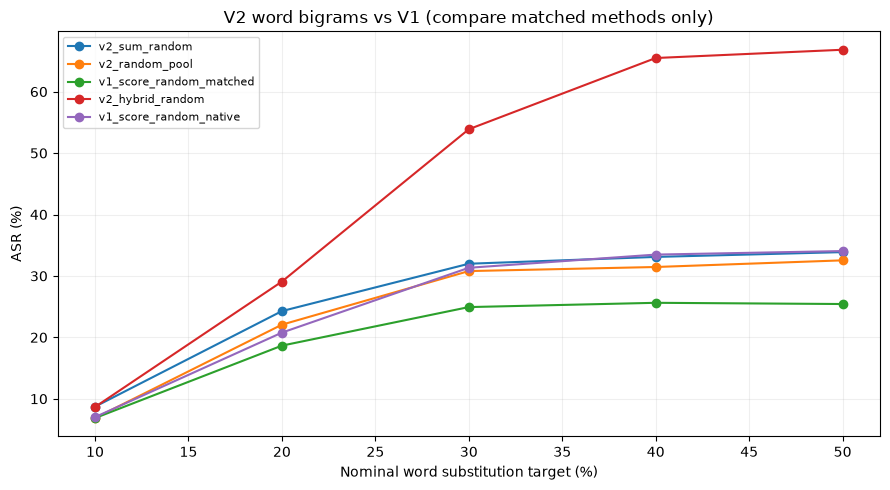

In [21]:
if not coverage_df.empty:
    cv = coverage_df.groupby(["min_support", "ratio"], as_index=False).agg(
        v2_coverage=("coverage_v2", "mean"),
        v1_coverage=("coverage_v1", "mean"),
        union_coverage=("coverage_union", "mean"),
        common_edit_ratio=("matched_edit_ratio", "mean"),
        below_budget_per_200=("texts_below_matched_budget", "mean"),
    )
    display(cv.round(4))

if not avg.empty:
    guided_rate = avg[avg["method"] == "v2_sum_guided"][
        ["min_support", "ratio", "mean_guided_fraction", "n_splits"]
    ]
    print("Fraction of replacements where guidance was supported by observed candidate bigrams:")
    display(guided_rate.round(4))

v1_csv = ROOT / "results" / "attacks" / "stealing_guided_v1_final" / "v1_asr_by_configuration.csv"
if v1_csv.is_file():
    v1_published = pd.read_csv(v1_csv)
    print("Existing V1 results (for reference, NOT matched-edit inference):")
    display(v1_published[(v1_published["min_support"] == 2) &
                         (v1_published["method"].isin(["score_random_synonyms", "fully_random"]))][
        ["ratio", "method", "asr_mean", "edit_mean"]
    ].round(4))

try:
    import matplotlib.pyplot as plt
    if not avg.empty:
        frame = avg[avg["min_support"] == REFERENCE_SUPPORT]
        fig, ax = plt.subplots(figsize=(9, 5))
        for name in ["v2_sum_random", "v2_random_pool", "v1_score_random_matched",
                     "v2_hybrid_random", "v1_score_random_native"]:
            sub = frame[frame["method"] == name].sort_values("ratio")
            if not sub.empty:
                ax.plot(sub["ratio"] * 100, sub["mean_asr"] * 100, marker="o", label=name)
        ax.set(xlabel="Nominal word substitution target (%)", ylabel="ASR (%)",
               title="V2 word bigrams vs V1 (compare matched methods only)")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)
        fig.tight_layout()
        fig.savefig(OUT_DIR / "v2_asr_by_ratio.png", dpi=170)
        plt.show()
except (ImportError, OSError, RuntimeError, ValueError) as exc:
    print("Optional chart skipped:", repr(exc))

## 11 — Exports, provenance and scientific interpretation

All derived tables are written as CSV/JSON; completed checkpoints remain unchanged. Existing outputs are compared against freshly computed frames before reuse, never silently overwritten with different numbers. Remember to preserve `results/attacks/stealing_guided_v2_bigram/` on your Mac: it is generated locally and large checkpoint JSONLs are ignored by Git.

**Interpretation guide:**

1. Compare `v2_sum_random` vs `v2_random_pool`: **does bigram ranking matter within the same eligible pool?**
2. Compare `v2_sum_random` vs `v1_score_random_matched`: **is context beneficial at exactly equal actual edits?**
3. Compare `v2_sum_guided` vs `v2_sum_random` and check **guided_fraction**; if near 0, the replacement-choice ablation is mostly random fallback.
4. Compare `v2_sum_random` vs `v2_max_random`: are two neighboring contexts more useful than the strongest one?
5. Analyze `v2_hybrid_random` separately: its improved coverage is a **different budget**, not a clean bigram advantage.
6. ASR alone does not establish semantic preservation or direct recovery of the watermark's token-level mechanism.
7. Tests are exploratory due to earlier tuning on the same 600 examples and overlapping splits. A future independent sample is needed for confirmatory p-values.

In [22]:
def export_csv_consistently(dataframe, filename, sort_keys, allow_updated_aggregates=False):
    """Allow pilot -> full-run growth, while checking prior split-level observations."""
    if dataframe.empty:
        print("Skipped empty export:", filename)
        return
    target = OUT_DIR / filename
    fresh = dataframe.sort_values(sort_keys).reset_index(drop=True)
    assert not fresh.duplicated(sort_keys).any(), (filename, "duplicate keys")
    if target.exists():
        prior = pd.read_csv(target).sort_values(sort_keys).reset_index(drop=True)
        assert list(prior.columns) == list(fresh.columns), (filename, "changed columns")
        assert not prior.duplicated(sort_keys).any(), (filename, "old duplicate keys")
        # Every previously published row must still be present with the same numbers.
        common = fresh.merge(prior[sort_keys], on=sort_keys, how="inner")
        common = common.sort_values(sort_keys).reset_index(drop=True)
        assert len(common) == len(prior), (filename, "previous result disappeared")
        if allow_updated_aggregates:
            assert "n_splits" in fresh.columns
            old_counts = prior[sort_keys + ["n_splits"]].rename(columns={"n_splits": "old_n"})
            compared = common.merge(old_counts, on=sort_keys, how="inner")
            assert (compared["n_splits"] >= compared["old_n"]).all(), "Lost split contributions"
            unchanged_keys = compared.loc[compared["n_splits"].eq(compared["old_n"]), sort_keys]
            if len(unchanged_keys):
                subset_new = common.merge(unchanged_keys, on=sort_keys, how="inner")
                subset_old = prior.merge(unchanged_keys, on=sort_keys, how="inner")
                pd.testing.assert_frame_equal(
                    subset_old.sort_values(sort_keys).reset_index(drop=True),
                    subset_new.sort_values(sort_keys).reset_index(drop=True),
                    check_dtype=False, check_exact=False, rtol=1e-8, atol=1e-8)
        else:
            pd.testing.assert_frame_equal(prior, common, check_dtype=False,
                                          check_exact=False, rtol=1e-8, atol=1e-8)
        if len(prior) == len(fresh) and (not allow_updated_aggregates or
                (common["n_splits"] == prior["n_splits"]).all()):
            print("Verified existing:", filename)
            return
        # Atomic replacement with verified extension (e.g. 1 pilot split -> 10 splits).
        with tempfile.NamedTemporaryFile(mode="w", suffix=".csv", prefix=".new_",
                                         dir=target.parent, delete=False) as handle:
            temp = Path(handle.name)
            fresh.to_csv(handle, index=False)
        temp.replace(target)
        print("Extended safely:", filename, f"({len(prior)} -> {len(fresh)} rows)")
    else:
        dataframe.to_csv(target, index=False)
        print("Saved:", filename)


export_csv_consistently(summary_df, "v2_split_summary.csv",
                        ["min_support", "split_seed", "ratio", "method"])
export_csv_consistently(avg, "v2_asr_aggregates.csv",
                        ["min_support", "ratio", "method"], allow_updated_aggregates=True)
export_csv_consistently(dataset_df, "v2_dataset_breakdown.csv",
                        ["min_support", "split_seed", "ratio", "method", "dataset"])
export_csv_consistently(coverage_df, "v2_coverage.csv",
                        ["min_support", "split_seed", "ratio"])
export_csv_consistently(contrast_df, "v2_contrasts.csv",
                        ["min_support", "split_seed", "ratio", "comparison"])
export_csv_consistently(paired_df, "v2_paired_successes.csv",
                        ["min_support", "split_seed", "ratio", "idx"])
export_csv_consistently(mcnemar_df, "v2_mcnemar_holm.csv",
                        ["min_support", "split_seed", "ratio", "comparison"])

manifest = {
    "experiment_id": EXPERIMENT_ID,
    "input_sha256": input_hashes,
    "completed_checkpoints": len(checkpoints),
    "expected_checkpoints": len(SPLIT_SEEDS) * len(MIN_SUPPORTS) * len(RATIOS),
    "pending_checkpoints": missing,
    "methods_matched": METHODS_MATCHED,
    "methods_descriptive": METHODS_DESCRIPTIVE,
    "primary_estimand": "ASR on originally detected WM outputs, per split",
    "matched_budget_definition": "min(round(r*n_words), n_v2_eligible, n_v1_eligible) per text",
    "warnings": [
        "All analyses exploratory; train/test splits overlap and dataset already used in V1 development",
        "Unobserved candidate bigrams are unknown, not evidence of a low watermark score",
        "Hybrid and V1-native are not guaranteed equal budgets",
        "No semantic-preservation metric",
    ],
}
manifest_path = OUT_DIR / "v2_manifest.json"
if manifest_path.exists():
    old = json.loads(manifest_path.read_text(encoding="utf-8"))
    # Progress fields are allowed to advance when resuming incomplete runs.
    fixed = {k: v for k, v in manifest.items() if k not in (
        "completed_checkpoints", "pending_checkpoints")}
    assert all(old.get(k) == v for k, v in fixed.items()), "Provenance mismatch"
manifest_path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
print("\nSaved V2 report manifest:", manifest_path)
if missing:
    print("INCOMPLETE experiment: rerun section 7 with full RUN_SPLIT_SEEDS / RUN_SUPPORTS")
else:
    print("COMPLETE experiment: all support × split × ratio checkpoints present")

Extended safely: v2_split_summary.csv (40 -> 800 rows)
Extended safely: v2_asr_aggregates.csv (40 -> 80 rows)
Extended safely: v2_dataset_breakdown.csv (120 -> 2400 rows)
Extended safely: v2_coverage.csv (5 -> 100 rows)
Extended safely: v2_contrasts.csv (25 -> 500 rows)
Extended safely: v2_paired_successes.csv (975 -> 19400 rows)
Verified existing: v2_mcnemar_holm.csv

Saved V2 report manifest: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v2_bigram/v2_manifest.json
COMPLETE experiment: all support × split × ratio checkpoints present


## References and notes

- **McNemar (1947)** — paired binary classification outcomes, evaluated here by the exact binomial form.
- **Holm (1979)** — sequentially rejective multiple-test adjustment.
- **WordNet** (Miller, 1995) — single-word lexical replacements.
- **Reference V1:** `notebooks/03_our_attacks/v1_unigram/stealing_guided_v1.ipynb` and `notebooks/04_exploratory/11_stealing_guided_position_selection.ipynb`.
- **Important:** word bigrams are a lexical heuristic. A V3 model-token bigram attack would operate closer to the mechanism of token-level watermark scoring.

**Before GitHub:** track derived `.csv`, `.json`, optional `.png` files as appropriate; exclude generated checkpoint `.jsonl` files per `.gitignore`. Document where original WM/NoWM datasets and raw checkpoints can be obtained or generated.